# 상세 페이지 모양: 1번 Pillow와 2번 HTML이 극단 입력에서 깨지는지 시험 (11/04)

21·앱의 상세 페이지는 그림 아래에 흰 글상자를 쌓는 모양이다. 이를 게임 홍보 랜딩 페이지 모양(어두운 배경, 구역 제목, 테두리 카드, 게임 화면·일러스트 구역)으로 바꾼다. 같은 사양을 두 방식으로 그려 비교한다.

| 방식 | 그리는 법 | 추가 설치 |
|---|---|---|
| 1번 Pillow | 글자·사각형·그림 위치를 코드가 계산해 그림 (21·앱 합성과 같은 방식) | 없음 |
| 2번 HTML → PNG | HTML·CSS로 짜고 Chromium으로 찍음 | `playwright` + `python -m playwright install chromium` |

- 구역: 첫 화면(대표 그림·이름표·제목·부제) → 게임 소개 → 게임 화면(스크린샷 + 레퍼런스 아트) → 일러스트(C·B 결과) → 굿즈 디자인 → 연출 사진 → 굿즈 구매 정보 → 버튼
- 처음 시안에서 깨진 4가지를 두 방식 모두 같은 규칙으로 고쳤다.
  1. 제목: 띄어쓰기 단위로 줄을 바꾸고 3줄 안에 들도록 56px → 30px까지 줄인다. 띄어쓰기 없이 긴 말은 글자 단위로 끊는다. 글자가 많으면 첫 화면 높이를 늘린다.
  2. 일러스트: 1~3장은 기울인 칸이고 장수에 맞춰 칸 폭을 계산한다. 4장부터는 2열 격자로 바꾼다.
  3. 구매 정보 칸: 값이 길면 21px → 15px까지 줄이고 그래도 길면 줄을 바꾼다. 빈 값은 빼고, 모두 비면 "(입력 없음)" 한 칸만 둔다.
  4. 테마 색: 대표 그림에서 채도 0.12 넘는 픽셀이 8% 미만이면 기본 남색(hue 0.6)을 쓴다.
- 시험 입력 30개: 기본(냥기사)에서 한 가지씩 극단으로 바꾼다. 긴 제목(한글·띄어쓰기 없음·영어), 긴 이름표·부제, 이모지, 긴 본문·URL, 일러스트 0~9장, 레퍼런스 0~13장, 스크린샷 없음, 가로 3:1·세로 1:3·64px 그림, 무채색·검정·흰색 대표 그림, 구매 정보 긴 값·빈 값·일부만, 문구 전부 빈 값.
- 자동 검사 (그린 글자·그림 위치를 모두 모아 셈)
  - 페이지 폭이 860px를 넘는가
  - 글자·그림이 페이지(0~860px) 밖으로 나가는가
  - 서로 다른 글자끼리 겹치는가 (1px 이하는 반올림 차이로 봄)
  - 1번은 글꼴에 없는 글자(이모지 등)를 빼고 그리므로, 뺀 글자 수를 따로 센다
- 이 PC(Windows)에서는 두 방식 모두 맑은 고딕으로 그린다. 1번은 맑은 고딕에 Black 굵기가 없어 굵은 글자(malgunbd)를 쓴다.
- 입력 그림·문구: 21 냥기사 결과(문구 `dp_copy_records.csv`, ③ F1cloth 목업, ④ R1n 연출 사진), 18 채택 조합 C 결과(`promo_c_lora`), `data/raw/nai` 스크린샷·레퍼런스 아트, 12 KayKit·0x72 C 결과. 구매 정보는 21 `PURCHASE` 예시와 같다.
- 실행: 별도 프로세스에서 두 방식을 차례로 그리고, 시험마다 진행 줄을 바로 출력한다(같은 내용을 `ds_run.log`에 남김). 처리 시간은 한 장을 그리는 시간이다(2번은 브라우저 시작 시간 제외, 따로 출력).
- 기록 (`outputs/detail_style/`)
  - `ds_config.json`, `ds_results.csv`, `ds_run.log`, `pages/`(시험별 PNG·HTML), `synth/`(극단 비율 시험 그림)
  - `ds_summary.png`, `ds_sheet_*.png`, `ds_zoom.png`
- 예상 시간: 시험 30개 × 두 방식, 약 2분 (클라우드 시험 기준 1번 장당 약 1초, 2번 약 2초)
- GPU는 쓰지 않는다.

## 설정

In [1]:
import importlib.metadata as md_
import importlib.util
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFont

ROOT = Path('..')
OUT_DIR = ROOT / 'outputs' / 'detail_style'
CHILD_DIR = OUT_DIR / '_child'
CHILD_DIR.mkdir(parents=True, exist_ok=True)
RAW_NAI = ROOT / 'data' / 'raw' / 'nai'
DP = ROOT / 'outputs' / 'detail_page'

# 글꼴: Windows 맑은 고딕(앱·21과 같음). 맑은 고딕에는 Black 굵기가 없어 굵은 글자를 씀. Windows가 아니면 Noto CJK(ttc 1번 = KR)
WIN = Path('C:/Windows/Fonts')
if (WIN / 'malgun.ttf').exists():
    FONTS = dict(reg=[str(WIN / 'malgun.ttf'), 0], bold=[str(WIN / 'malgunbd.ttf'), 0], black=[str(WIN / 'malgunbd.ttf'), 0])
else:
    N = '/usr/share/fonts/opentype/noto/'
    FONTS = dict(reg=[N + 'NotoSansCJK-Regular.ttc', 1], bold=[N + 'NotoSansCJK-Bold.ttc', 1], black=[N + 'NotoSansCJK-Black.ttc', 1])
for k, (p, _) in FONTS.items():
    assert Path(p).exists(), p
_ko = [f.name for f in font_manager.fontManager.ttflist if f.name in ('Malgun Gothic', 'Noto Sans CJK KR')]
if _ko:
    plt.rcParams['font.family'] = _ko[0]
plt.rcParams['axes.unicode_minus'] = False

# 입력 그림 (모두 이미 만든 결과·데이터. 새로 생성하지 않음)
LORA = ROOT / 'outputs' / 'promo_c_lora'
A = dict(
    hero=LORA / 'CL_zero__lora-zero-n50__ipa__B0_s0.png',          # 18 채택 조합(LoRA 50장 + IP-Adapter) 여름 바다 장면
    hero_kaykit=ROOT / 'outputs' / 'promo_c' / 'C_B2_kaykit_ipa_s0.png',
    hero_x72=ROOT / 'outputs' / 'promo_c' / 'C_B4_x72_ipa_s0.png',
    shot=RAW_NAI / 'game screenshot, side view, 2d side-scrolling adventure, no humans, black cat ad s-2737766560.png',
    refs=[RAW_NAI / n for n in [
        'game screenshot, side view, 2d side-scrolling adventure, no humans, black cat ad s-106634957.png',
        'no humans, no animals, scenery, forest path with sunlight through trees, small s s-4189831116.png',
        'no humans, no animals, scenery, tavern interior, wooden tables, hanging lamps, f s-2683784629.png',
        'no humans, no animals, scenery, wide green valley with small red roofed villages s-3790772847.png',
        'no humans, black cat adventurer standing upright, yellow eyes, red wide-brim hat s-1864801818.png',
        'no humans, old grey owl wizard, long blue robe, wooden staff, small round hat, r s-2667676876.png',
        'no humans, white rabbit merchant, round glasses, brown apron, large backpack ful s-3209990522.png',
        'no humans, item icon set, olive green kite shield with white cat face emblem, sh s-3850245942.png']],
    illus=[LORA / f'CL_zero__lora-zero-n50__ipa__{b}_s0.png' for b in ['B1', 'B6', 'B7']],  # 할로윈 숲, 봄 벚꽃, 겨울 마을
    mockup=DP / 'images' / 'mockup' / 'F1cloth__tshirt_02__nai.png',
    d=DP / 'images' / 'd' / 'R1n__tshirt_02__desk.png',
    forest=RAW_NAI / 'no humans, no animals, scenery, forest path with sunlight through trees, small s s-4189831116.png',
)
for k, v in A.items():
    for p in (v if isinstance(v, list) else [v]):
        assert p.exists(), p
A = {k: ([str(p.resolve()) for p in v] if isinstance(v, list) else str(v.resolve())) for k, v in A.items()}

# 문구: 21 냥기사 문구 기록 그대로, 구매 정보는 21 "설정" 셀 PURCHASE 예시와 같음
_rec = pd.read_csv(DP / 'dp_copy_records.csv', keep_default_na=False).set_index('id')
_j = lambda i: json.loads(_rec.loc[i, 'text'])
TEXTS = dict(eyebrow='냥기사의 여행', title=_j('nai__title')['title'], info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임',
             intro=_j('nai__intro')['store'], sns=_j('nai__intro')['sns'], mock_text=' '.join(_j('nai__mockup')['copy']),
             d_text=' '.join(_j('nai__staging')['copy']),
             purchase={'상품명': '냥기사의 여행 일러스트 티셔츠', '판매가': '29,000원', '옵션': 'S / M / L / XL', '배송비': '3,000원', '출고': '주문 후 3일 이내'})

HAS_PW = importlib.util.find_spec('playwright') is not None
for p in ['pillow', 'fonttools', 'numpy', 'pandas', 'matplotlib', 'playwright']:
    try:
        print(f'{p} {md_.version(p)}')
    except md_.PackageNotFoundError:
        print(f'{p} 없음')
print('글꼴:', {k: Path(v[0]).name for k, v in FONTS.items()}, '| 21 문구 기록 수정 시각:',
      time.strftime('%Y-%m-%d %H:%M', time.localtime((DP / 'dp_copy_records.csv').stat().st_mtime)))
if not HAS_PW:
    print('2번 HTML을 돌리려면 Anaconda Prompt(myenv)에서 아래 두 줄을 실행한 뒤 커널을 다시 시작한다:\n'
          '  pip install playwright==1.56.0\n  python -m playwright install chromium')

pillow 12.3.0
fonttools 4.63.0
numpy 2.2.6
pandas 3.0.6
matplotlib 3.11.2
playwright 1.56.0
글꼴: {'reg': 'malgun.ttf', 'bold': 'malgunbd.ttf', 'black': 'malgunbd.ttf'} | 21 문구 기록 수정 시각: 2026-11-03 09:53


## 공통 코드 (페이지 크기·테마 색·시험 입력 30개)

In [2]:
CODE_COMMON = r'''# 1번(Pillow)과 2번(HTML)이 같이 쓰는 부분: 페이지 크기, 테마 색, 시험 입력 30개
import colorsys
from pathlib import Path

import numpy as np
from PIL import Image

W, PAD = 860, 64          # 상세 페이지 가로 860px (21과 같음), 좌우 여백
CW = W - 2 * PAD
DEFAULT_HUE = 0.6         # 색이 거의 없는 그림일 때 쓰는 기본 남색
SAT_MIN, SAT_SHARE = 0.12, 0.08  # 채도 0.12 넘는 픽셀이 8% 미만이면 기본 남색


def theme(img):
    # 대표 그림에서 채도 있는 픽셀의 색상(hue) 최빈값을 테마 색으로 씀
    a = np.asarray(img.convert('RGB').resize((128, 128))).reshape(-1, 3) / 255.0
    hsv = np.array([colorsys.rgb_to_hsv(*p) for p in a])
    sel = hsv[hsv[:, 1] > SAT_MIN]
    if len(sel) / len(hsv) < SAT_SHARE:
        h, src = DEFAULT_HUE, 'default'
    else:
        hist, e = np.histogram(sel[:, 0], bins=24, range=(0, 1))
        h, src = (e[hist.argmax()] + e[hist.argmax() + 1]) / 2, 'image'
    rgb = lambda s, v: tuple(int(x * 255) for x in colorsys.hsv_to_rgb(h, s, v))
    return dict(bg=rgb(.6, .09), bg2=rgb(.55, .16), accent=rgb(.45, .98), line=rgb(.5, .6), ink=(232, 241, 247), sub=(157, 179, 194),
                hue=round(float(h), 3), source=src)


def hexc(c):
    return '#%02x%02x%02x' % c


def synth(A, out_dir):
    # 극단 비율·크기·무채색 시험용 그림
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    shot = Image.open(A['shot']).convert('RGB')
    shot.resize((1500, 500)).save(out_dir / 'wide.png')
    shot.resize((400, 1200)).save(out_dir / 'tall.png')
    shot.resize((64, 64)).save(out_dir / 'tiny.png')
    Image.open(A['forest']).convert('L').convert('RGB').save(out_dir / 'gray.png')
    Image.new('RGB', (1024, 1024), (6, 6, 6)).save(out_dir / 'black.png')
    Image.new('RGB', (1024, 1024), (252, 252, 252)).save(out_dir / 'white.png')
    return {k: str(out_dir / f'{k}.png') for k in ['wide', 'tall', 'tiny', 'gray', 'black', 'white']}


def cases(A, T, S):
    # A: 그림 경로, T: 문구, S: synth 그림. 시험마다 기본(냥기사)에서 한 가지씩 극단으로 바꿈
    base = dict(hero=A['hero'], eyebrow=T['eyebrow'], title=T['title'], info=T['info'], intro=T['intro'], sns=T['sns'],
                shot=A['shot'], refs=A['refs'], illus=A['illus'], mockup=A['mockup'], mock_text=T['mock_text'],
                d=A['d'], d_text=T['d_text'], purchase=T['purchase'])
    long_ko = '4인 협동으로 즐기는 16비트 픽셀 던전 탐험과 보물상자 수집의 모든 것을 지금 바로 확인하세요'
    nospace = '슈퍼울트라하이퍼메가던전크롤러리마스터디럭스에디션완전판한정수량특별패키지'
    long_en = 'THE LEGEND OF THE NYANG KNIGHT AND THE MOONLIT FOREST ADVENTURE REMASTERED'
    url = 'https://store.steampowered.com/app/1234567/nyang_knight_adventure_remastered_deluxe_edition/'
    long_body = ' '.join(T['intro'] * 4)
    il = A['illus'] + [A['hero']] + A['refs'][:5]
    c = {
        '01 기본(냥기사)': {},
        '02 KayKit C 그림': dict(hero=A['hero_kaykit']),
        '03 0x72 C 그림': dict(hero=A['hero_x72']),
        '04 긴 제목(한글)': dict(title=long_ko),
        '05 띄어쓰기 없는 제목': dict(title=nospace),
        '06 긴 제목(영어)': dict(title=long_en),
        '07 긴 게임 이름(이름표)': dict(eyebrow=nospace + ' ' + long_en),
        '08 긴 부제': dict(info=long_body[:220]),
        '09 이모지 제목': dict(title='🔥 신규 업데이트! 냥기사 ✨ 겨울 이벤트 🎄'),
        '10 긴 본문·URL': dict(intro=[long_body, url], sns=url + ' ' + T['sns'], mock_text=long_body, d_text=nospace * 3),
        '11 일러스트 0장': dict(illus=[]),
        '12 일러스트 1장': dict(illus=il[:1]),
        '13 일러스트 2장': dict(illus=il[:2]),
        '14 일러스트 4장': dict(illus=il[:4]),
        '15 일러스트 5장': dict(illus=il[:5]),
        '16 일러스트 9장': dict(illus=il[:9]),
        '17 레퍼런스 0장·스샷 없음': dict(refs=[], shot=None),
        '18 레퍼런스 1장': dict(refs=A['refs'][:1]),
        '19 레퍼런스 13장': dict(refs=A['refs'] + A['illus'] + [A['hero'], S['gray']] + A['refs'][:1]),
        '20 스샷 없음(C 결과로 대신)': dict(shot=A['illus'][0]),
        '21 가로 3:1 그림 전부': dict(hero=S['wide'], shot=S['wide'], mockup=S['wide'], d=S['wide'], refs=[S['wide']] * 4, illus=[S['wide']] * 3),
        '22 세로 1:3 그림 전부': dict(hero=S['tall'], shot=S['tall'], mockup=S['tall'], d=S['tall'], refs=[S['tall']] * 4, illus=[S['tall']] * 5),
        '23 64px 작은 그림': dict(hero=S['tiny'], shot=S['tiny'], refs=[S['tiny']] * 2),
        '24 무채색 대표 그림': dict(hero=S['gray']),
        '25 검정 대표 그림': dict(hero=S['black']),
        '26 흰색 대표 그림': dict(hero=S['white']),
        '27 구매 정보 긴 값': dict(purchase={'상품명': long_ko + ' ' + nospace, '판매가': '1,234,567,890원 (부가세·배송비 별도)',
                                            '옵션': 'S / M / L / XL / 2XL / 3XL / 4XL / 5XL / 블랙 / 화이트', '배송비': nospace,
                                            '출고': '주문 후 3일 이내 (주말·공휴일 제외, 제주·도서산간 추가 2~3일)'}),
        '28 구매 정보 빈 값': dict(purchase={'상품명': '', '판매가': '', '옵션': '', '배송비': '', '출고': ''}),
        '29 구매 정보 일부만': dict(purchase={'상품명': '', '판매가': T['purchase']['판매가'], '옵션': '', '배송비': '', '출고': T['purchase']['출고']}),
        '30 문구 빈 값': dict(intro=[], sns='', mock_text='', d_text='', title='', info=''),
    }
    return {k: {**base, **v} for k, v in c.items()}
'''
(CHILD_DIR / 'common26.py').write_text(CODE_COMMON, encoding='utf-8')
print('저장:', CHILD_DIR / 'common26.py', len(CODE_COMMON.splitlines()), '줄')

저장: ..\outputs\detail_style\_child\common26.py 92 줄


## 1번 Pillow 코드

In [3]:
CODE_PIL = r'''# 1번: Pillow 렌더러. 그린 글자·그림의 위치를 모두 기록해 검사에 씀
import numpy as np
from fontTools.ttLib import TTCollection
from PIL import Image, ImageDraw, ImageFilter, ImageFont

from common26 import CW, PAD, W, theme

FONTS, _CMAP, _cache = {}, set(), {}


def setup(fonts):
    # fonts: {'reg': [경로, ttc 번호], 'bold': ..., 'black': ...}. 글꼴에 있는 글자 목록(cmap)도 읽음
    from fontTools.ttLib import TTFont
    FONTS.update(fonts)
    path, idx = fonts['reg']
    _CMAP.update(TTCollection(path).fonts[idx].getBestCmap() if path.lower().endswith('.ttc') else TTFont(path).getBestCmap())


def F(kind, size):
    k = (kind, size)
    if k not in _cache:
        path, idx = FONTS[kind]
        _cache[k] = ImageFont.truetype(path, size, index=idx)
    return _cache[k]


def clean(text):
    # 글꼴에 없는 글자(이모지 등)는 네모로 그려지므로 빼고, 뺀 수를 기록함
    keep = ''.join(ch for ch in text if ord(ch) in _CMAP or ch in ' \n')
    return ' '.join(keep.split()), len(text.replace(' ', '')) - len(keep.replace(' ', ''))


def tokens(text, font, max_w, d):
    # 띄어쓰기 단위로 자르고(한국어 keep-all), 한 덩어리가 칸보다 길면 글자 단위로 나눔
    out = []
    for w in text.split(' '):
        if d.textlength(w, font=font) <= max_w:
            out.append(w)
            continue
        cur = ''
        for ch in w:
            if d.textlength(cur + ch, font=font) > max_w and cur:
                out.append(cur)
                cur = ch
            else:
                cur += ch
        out.append(cur)
    return out


def wrap(text, font, max_w):
    d = ImageDraw.Draw(Image.new('RGB', (8, 8)))
    lines, cur = [], ''
    for w in tokens(text, font, max_w, d):
        t = (cur + ' ' + w).strip()
        if d.textlength(t, font=font) <= max_w:
            cur = t
        else:
            if cur:
                lines.append(cur)
            cur = w
    if cur:
        lines.append(cur)
    return lines


def fit(text, kind, big, small, max_w, max_lines):
    # 줄 수가 max_lines 안에 드는 가장 큰 글자 크기. 끝까지 안 되면 가장 작은 크기로 줄을 늘림
    for s in range(big, small - 1, -2):
        ls = wrap(text, F(kind, s), max_w)
        if len(ls) <= max_lines:
            return ls, F(kind, s)
    return wrap(text, F(kind, small), max_w), F(kind, small)


def add_glow(im, glow, k):
    return Image.fromarray(np.clip(np.asarray(im, int) + (np.asarray(glow, int) * k).astype(int), 0, 255).astype('uint8'))


def cover(img, w, h):
    s = max(w / img.width, h / img.height)
    t = img.resize((max(w, round(img.width * s)), max(h, round(img.height * s))), Image.LANCZOS)
    x, y = (t.width - w) // 2, (t.height - h) // 2
    return t.crop((x, y, x + w, y + h))


def contain_w(img, w, max_h, bg):
    # 폭에 맞추되 너무 길면 높이 max_h 안에 넣고 남는 곳은 배경색
    s = min(w / img.width, max_h / img.height)
    t = img.resize((max(1, round(img.width * s)), max(1, round(img.height * s))), Image.LANCZOS)
    if t.width == w:
        return t
    out = Image.new('RGB', (w, t.height), bg)
    out.paste(t, ((w - t.width) // 2, 0))
    return out


class Page:
    def __init__(self, T):
        self.T, self.parts, self.texts, self.imgs, self.dropped = T, [], [], [], 0
        self.cur, self.secs = 'hero', []  # 구역 이름별 세로 범위 (확대 비교용)

    def canvas(self, h):
        return Image.new('RGB', (W, h), self.T['bg'])

    def part(self, im, texts=(), imgs=()):
        y0 = sum(p.height for p in self.parts)
        self.parts.append(im)
        if self.secs and self.secs[-1][0] == self.cur:
            self.secs[-1][2] = y0 + im.height
        else:
            self.secs.append([self.cur, y0, y0 + im.height])
        self.texts += [(n, (b[0], b[1] + y0, b[2], b[3] + y0)) for n, b in texts]
        self.imgs += [(n, (b[0], b[1] + y0, b[2], b[3] + y0)) for n, b in imgs]

    def lines_block(self, lines, font, color, lh, top=0, bottom=0, name='text'):
        step = int(font.size * lh)
        im = self.canvas(top + step * len(lines) + bottom)
        d = ImageDraw.Draw(im)
        tx = []
        for i, l in enumerate(lines):
            xy = (W // 2, top + i * step + step // 2)
            d.text(xy, l, font=font, fill=color, anchor='mm')
            tx.append((name, d.textbbox(xy, l, font=font, anchor='mm')))
        return im, tx

    def text(self, text, kind, size, color, max_w=CW, lh=1.85, top=0, bottom=0, name='text'):
        text, n = clean(text)
        self.dropped += n
        if not text:
            return
        im, tx = self.lines_block(wrap(text, F(kind, size), max_w), F(kind, size), color, lh, top, bottom, name)
        self.part(im, tx)

    def hero(self, img, eyebrow, title, info):
        T = self.T
        eyebrow, n1 = clean(eyebrow)
        title, n2 = clean(title)
        info, n3 = clean(info)
        self.dropped += n1 + n2 + n3
        e_lines, fe = fit(eyebrow, 'bold', 15, 11, CW - 40, 2) if eyebrow else ([], F('bold', 15))
        t_lines, ft = fit(title, 'black', 56, 30, CW, 3) if title else ([], F('black', 56))
        i_lines = wrap(info, F('reg', 19), CW) if info else []
        e_step, t_step, i_step = int(fe.size * 1.5), int(ft.size * 1.22), int(19 * 1.5)
        block = (len(e_lines) * e_step + 18 if e_lines else 0) + len(t_lines) * t_step + (12 + len(i_lines) * i_step if i_lines else 0)
        h = max(640, block + 56 + 300)  # 글자 위로 그림이 300px 이상 보이게 하고 넘치면 첫 화면을 늘림
        im = cover(img.convert('RGB'), W, h)
        top = h - 56 - block
        a = np.zeros((h, 1), np.float32)
        g0 = max(0, top - 220)
        a[g0:top, 0] = np.linspace(0, .75, top - g0)
        a[top:, 0] = np.linspace(.75, 1, h - top)
        im = Image.composite(Image.new('RGB', (W, h), T['bg']), im, Image.fromarray((a * 255).astype('uint8'), 'L').resize((W, h)))
        tx, y = [], top
        d = ImageDraw.Draw(im)
        if e_lines:
            ew = max(d.textlength(l, font=fe) for l in e_lines) + 40
            d.rounded_rectangle((W / 2 - ew / 2, y - 4, W / 2 + ew / 2, y + len(e_lines) * e_step + 4), radius=16, fill=T['bg'], outline=T['line'])
            for l in e_lines:
                xy = (W // 2, y + e_step // 2)
                d.text(xy, l, font=fe, fill=T['accent'], anchor='mm')
                tx.append(('eyebrow', d.textbbox(xy, l, font=fe, anchor='mm')))
                y += e_step
            y += 18
        glow = Image.new('RGB', (W, h), (0, 0, 0))
        gd = ImageDraw.Draw(glow)
        for i, l in enumerate(t_lines):
            gd.text((W // 2, y + i * t_step + t_step // 2), l, font=ft, fill=T['accent'], anchor='mm')
        im = add_glow(im, glow.filter(ImageFilter.GaussianBlur(10)), .9)
        d = ImageDraw.Draw(im)
        for l in t_lines:
            xy = (W // 2, y + t_step // 2)
            d.text((xy[0], xy[1] + 4), l, font=ft, fill=(0, 0, 0), anchor='mm')
            d.text(xy, l, font=ft, fill=(255, 255, 255), anchor='mm')
            tx.append(('title', d.textbbox(xy, l, font=ft, anchor='mm')))
            y += t_step
        if i_lines:
            y += 12
            for l in i_lines:
                xy = (W // 2, y + i_step // 2)
                d.text(xy, l, font=F('reg', 19), fill=T['sub'], anchor='mm')
                tx.append(('info', d.textbbox(xy, l, font=F('reg', 19), anchor='mm')))
                y += i_step
        self.part(im, tx, [('hero', (0, 0, W, h))])

    def heading(self, label, title):
        T = self.T
        self.cur = title
        im = self.canvas(190)
        d = ImageDraw.Draw(im)
        d.line((W // 2, 0, W // 2, 44), fill=T['line'], width=1)
        d.text((W // 2, 82), '  '.join(label), font=F('bold', 14), fill=T['accent'], anchor='mm')
        d.text((W // 2, 124), title, font=F('black', 36), fill=(255, 255, 255), anchor='mm')
        tx = [('label', d.textbbox((W // 2, 82), '  '.join(label), font=F('bold', 14), anchor='mm')),
              ('h2', d.textbbox((W // 2, 124), title, font=F('black', 36), anchor='mm'))]
        glow = Image.new('RGB', (W, 190), (0, 0, 0))
        ImageDraw.Draw(glow).rectangle((W // 2 - 28, 160, W // 2 + 28, 163), fill=T['accent'])
        im = add_glow(im, glow.filter(ImageFilter.GaussianBlur(6)), 1)
        ImageDraw.Draw(im).rectangle((W // 2 - 28, 160, W // 2 + 28, 163), fill=T['accent'])
        self.part(im, tx)

    def quote(self, text):
        T = self.T
        text, n = clean(text)
        self.dropped += n
        if not text:
            return
        lines = wrap('“' + text + '”', F('bold', 21), 600)
        im, tx = self.lines_block(lines, F('bold', 21), T['accent'], 1.6, 24 + 32, 24, 'quote')
        d = ImageDraw.Draw(im)
        d.line((110, 32, W - 110, 32), fill=T['line'])
        d.line((110, im.height - 1, W - 110, im.height - 1), fill=T['line'])
        self.part(im, tx)

    def card(self, img, cw, max_h=820, name='card'):
        T = self.T
        inner = contain_w(img.convert('RGB'), cw - 20, max_h, T['bg2'])
        h = inner.height + 20 + 72
        im = self.canvas(h)
        x0, y0 = (W - cw) // 2, 36
        box = (x0, y0, x0 + cw, y0 + inner.height + 20)
        glow = Image.new('RGB', (W, h), (0, 0, 0))
        ImageDraw.Draw(glow).rounded_rectangle(box, radius=14, outline=T['accent'], width=6)
        im = add_glow(im, glow.filter(ImageFilter.GaussianBlur(18)), .35)
        d = ImageDraw.Draw(im)
        d.rounded_rectangle(box, radius=14, fill=T['bg2'], outline=T['line'])
        m = Image.new('L', inner.size, 0)
        ImageDraw.Draw(m).rounded_rectangle((0, 0, inner.width - 1, inner.height - 1), radius=8, fill=255)
        im.paste(inner, (x0 + 10, y0 + 10), m)
        self.part(im, imgs=[(name, box)])

    def grid(self, imgs, cols, ratio, gap=12, name='grid'):
        T = self.T
        tw = min(240 if ratio == 1 else 10 ** 6, (CW - gap * (cols - 1)) // cols)
        th = int(tw * ratio)
        rows = (len(imgs) + cols - 1) // cols
        im = self.canvas(rows * (th + gap) + 20)
        d = ImageDraw.Draw(im)
        boxes = []
        for i, g in enumerate(imgs):
            r, c = divmod(i, cols)
            n_row = min(cols, len(imgs) - r * cols)
            x0 = (W - (n_row * tw + (n_row - 1) * gap)) // 2  # 마지막 줄이 덜 차도 가운데 정렬
            x, y = x0 + c * (tw + gap), r * (th + gap)
            t = cover(g.convert('RGB'), tw, th)
            m = Image.new('L', (tw, th), 0)
            ImageDraw.Draw(m).rounded_rectangle((0, 0, tw - 1, th - 1), radius=10, fill=255)
            im.paste(t, (x, y), m)
            d.rounded_rectangle((x, y, x + tw - 1, y + th - 1), radius=10, outline=T['line'])
            boxes.append((name, (x, y, x + tw, y + th)))
        self.part(im, imgs=boxes)

    def slant(self, imgs, h=420):
        # 1~3장: 기울인 칸, 4장 이상: 2열 격자 (16:10)
        T = self.T
        n = len(imgs)
        if n >= 4:
            return self.grid(imgs, 2, 10 / 16, gap=14, name='illus')
        ov = 100 if n > 1 else 0
        pw = min(330 if n > 1 else 520, (W - 48 + ov * (n - 1)) // n)
        total = pw * n - ov * (n - 1)
        x0 = (W - total) // 2
        k = int(pw * .28) if n > 1 else int(pw * .12)
        im = self.canvas(h + 40)
        boxes = []
        for i, g in enumerate(imgs):
            x = x0 + i * (pw - ov)
            t = cover(g.convert('RGB'), pw, h)
            m = Image.new('L', (pw, h), 0)
            ImageDraw.Draw(m).polygon([(k, 0), (pw, 0), (pw - k, h), (0, h)], fill=255)
            im.paste(t, (x, 40), m)
            ImageDraw.Draw(im).line([(x + k, 40), (x, 40 + h)], fill=T['accent'], width=4)
            boxes.append(('illus', (x, 40, x + pw, 40 + h)))
        self.part(im, imgs=boxes)

    def full(self, img, max_h=900):
        T = self.T
        im = contain_w(img.convert('RGB'), W, max_h, T['bg'])
        h = im.height
        a = np.ones((h, 1), np.float32)
        k = max(1, int(h * .12))
        a[:k, 0] = np.linspace(0, 1, k)
        a[-k:, 0] = np.linspace(1, 0, k)
        out = self.canvas(h + 36)
        out.paste(Image.composite(im, Image.new('RGB', im.size, T['bg']), Image.fromarray((a * 255).astype('uint8'), 'L').resize((W, h))), (0, 36))
        self.part(out, imgs=[('d', (0, 36, W, 36 + h))])

    def tiles(self, info, note):
        T = self.T
        vals = {}
        for k, v in info.items():
            v, n = clean(v)
            self.dropped += n
            if v:
                vals[k] = v
        if not vals:
            vals = {'구매 정보': '(입력 없음)'}
        wide = [k for k in vals if k in ('상품명', '출고', '구매 정보')]
        small = [k for k in vals if k not in wide]
        rows = [[k] for k in wide[:1]] + ([small] if small else []) + [[k] for k in wide[1:]]
        gap, tx, boxes, y = 14, [], [], 36
        layout = []
        for r in rows:
            tw = (CW - gap * (len(r) - 1)) / len(r)
            cells = []
            for k in r:
                ls, fv = fit(vals[k], 'bold', 21, 15, int(tw) - 24, 2)
                cells.append((k, ls, fv))
            th = 32 + max(len(ls) * int(fv.size * 1.4) for _, ls, fv in cells) + 22
            layout.append((r, tw, th, cells))
        im = self.canvas(36 + sum(th + gap for _, _, th, _ in layout) + 40)
        d = ImageDraw.Draw(im)
        for r, tw, th, cells in layout:
            for i, (k, ls, fv) in enumerate(cells):
                x = PAD + i * (tw + gap)
                d.rounded_rectangle((x, y, x + tw, y + th), radius=12, fill=T['bg2'], outline=T['line'])
                boxes.append(('tile', (int(x), y, int(x + tw), y + th)))
                d.text((x + tw / 2, y + 22), k, font=F('reg', 14), fill=T['sub'], anchor='mm')
                tx.append(('tile_key', d.textbbox((x + tw / 2, y + 22), k, font=F('reg', 14), anchor='mm')))
                step = int(fv.size * 1.4)
                for j, l in enumerate(ls):
                    xy = (x + tw / 2, y + 36 + j * step + step // 2)
                    d.text(xy, l, font=fv, fill=(255, 255, 255), anchor='mm')
                    tx.append(('tile_val', d.textbbox(xy, l, font=fv, anchor='mm')))
            y += th + gap
        d.text((W // 2, y + 12), note, font=F('reg', 13), fill=T['sub'], anchor='mm')
        tx.append(('note', d.textbbox((W // 2, y + 12), note, font=F('reg', 13), anchor='mm')))
        self.part(im, tx, boxes)

    def cta(self, text):
        T = self.T
        im = self.canvas(150)
        f = F('black', 21)
        tw = ImageDraw.Draw(im).textlength(text, font=f) + 108
        box = (W / 2 - tw / 2, 40, W / 2 + tw / 2, 100)
        glow = Image.new('RGB', (W, 150), (0, 0, 0))
        ImageDraw.Draw(glow).rounded_rectangle(box, radius=30, fill=T['accent'])
        im = add_glow(im, glow.filter(ImageFilter.GaussianBlur(14)), .5)
        d = ImageDraw.Draw(im)
        d.rounded_rectangle(box, radius=30, fill=T['accent'])
        d.text((W // 2, 70), text, font=f, fill=T['bg'], anchor='mm')
        self.part(im, [('cta', d.textbbox((W // 2, 70), text, font=f, anchor='mm'))])

    def build(self):
        out = Image.new('RGB', (W, sum(p.height for p in self.parts)), self.T['bg'])
        y = 0
        for p in self.parts:
            out.paste(p, (0, y))
            y += p.height
        return out


def render(spec):
    O = lambda p: Image.open(p)
    hero = O(spec['hero'])
    T = theme(hero)
    pg = Page(T)
    pg.hero(hero, spec['eyebrow'], spec['title'], spec['info'])
    if spec['intro'] or spec['sns']:
        pg.heading('ABOUT THE GAME', '게임 소개')
        pg.text(' '.join(spec['intro']), 'reg', 20, T['ink'], max_w=600, top=24)
        pg.quote(spec['sns'])
        pg.part(pg.canvas(40))
    if spec['shot'] or spec['refs']:
        pg.heading('GAME SCREENS', '게임 화면')
        if spec['shot']:
            pg.card(O(spec['shot']), CW, max_h=900, name='shot')
        if spec['refs']:
            pg.grid([O(p) for p in spec['refs']], min(4, len(spec['refs'])), 1, name='ref')
        pg.part(pg.canvas(30))
    if spec['illus']:
        pg.heading('ILLUSTRATION', '일러스트')
        pg.slant([O(p) for p in spec['illus']])
        pg.part(pg.canvas(40))
    pg.heading('GOODS DESIGN', '굿즈 디자인')
    pg.card(O(spec['mockup']), 640, name='mockup')
    pg.text(spec['mock_text'], 'reg', 20, T['ink'], max_w=640, bottom=40)
    pg.heading('ON YOUR DESK', '연출 사진')
    pg.full(O(spec['d']))
    pg.text(spec['d_text'], 'reg', 20, T['ink'], max_w=680, top=16, bottom=40)
    pg.heading('GOODS INFO', '굿즈 구매 정보')
    pg.tiles(spec['purchase'], '※ 서비스 시연용 가상 예시 입력이며 실제 판매 정보가 아닙니다.')
    pg.cta('굿즈 구매하러 가기 ›')
    return pg.build(), pg.texts, pg.imgs, dict(dropped=pg.dropped, theme_source=T['source'], hue=T['hue'], sections=pg.secs)
'''
(CHILD_DIR / 'pil26.py').write_text(CODE_PIL, encoding='utf-8')
print('저장:', CHILD_DIR / 'pil26.py', len(CODE_PIL.splitlines()), '줄')

저장: ..\outputs\detail_style\_child\pil26.py 384 줄


## 2번 HTML 코드

In [4]:
CODE_HTML = r'''# 2번: HTML 렌더러. 1번과 같은 사양을 HTML·CSS로 짜고 Chromium으로 찍음. 검사용 위치는 브라우저에서 읽음
import html
import time
from pathlib import Path

from PIL import Image

from common26 import CW, W, hexc, theme

CSS = """
*{box-sizing:border-box;margin:0;padding:0}
body{width:%(W)dpx;background:var(--bg);color:var(--ink);font-family:"Malgun Gothic","Noto Sans CJK KR","Noto Color Emoji","Segoe UI Emoji",sans-serif;
  word-break:keep-all;overflow-wrap:anywhere}
.hero{position:relative;min-height:640px;display:flex;flex-direction:column;justify-content:flex-end;padding:300px 64px 56px;overflow:hidden}
.hero>img{position:absolute;inset:0;width:100%%;height:100%%;object-fit:cover}
.hero::after{content:"";position:absolute;inset:0;background:linear-gradient(0deg,var(--bg) 0,var(--bgA) var(--block),transparent var(--fade))}
.hero .txt{position:relative;z-index:2;text-align:center}
.eyebrow{display:inline-block;max-width:100%%;font-size:15px;line-height:1.5;letter-spacing:.3em;color:var(--accent);font-weight:700;padding:4px 18px;border:1px solid var(--line);border-radius:16px;background:var(--bg)}
.hero h1{margin-top:18px;font-size:56px;line-height:1.22;font-weight:900;color:#fff;text-shadow:0 0 18px var(--glow),0 4px 0 rgba(0,0,0,.6)}
.hero .info{margin-top:12px;font-size:19px;line-height:1.5;color:var(--sub)}
section{padding:0 64px;text-align:center;position:relative}
.head{padding-top:0;height:190px;position:relative}
.head::before{content:"";position:absolute;top:0;left:50%%;width:1px;height:44px;background:var(--line)}
.label{position:absolute;top:73px;left:0;right:0;font-size:14px;letter-spacing:.4em;color:var(--accent);font-weight:700}
.head h2{position:absolute;top:100px;left:0;right:0;font-size:36px;line-height:48px;font-weight:900;color:#fff}
.bar{position:absolute;top:160px;left:50%%;width:56px;height:4px;margin-left:-28px;background:var(--accent);box-shadow:0 0 12px var(--accent)}
p.body{margin:0 auto;font-size:20px;line-height:1.85}
.quote{margin:32px auto 0;max-width:620px;padding:22px 10px;font-size:21px;line-height:1.6;font-weight:700;color:var(--accent);border-top:1px solid var(--line);border-bottom:1px solid var(--line)}
.card{margin:36px auto 0;padding:10px;border:1px solid var(--line);border-radius:14px;background:var(--bg2);box-shadow:0 0 40px var(--glow2)}
.card img{display:block;width:100%%;max-height:var(--maxh);object-fit:contain;border-radius:8px}
.grid{margin:14px auto 0;display:flex;flex-wrap:wrap;justify-content:center;gap:12px}
.grid div{overflow:hidden;border:1px solid var(--line);border-radius:10px;background:var(--bg2)}
.grid img{width:100%%;height:100%%;object-fit:cover;display:block}
.slant{margin:40px auto 0;height:420px;display:flex;justify-content:center}
.slant div{height:100%%;position:relative;flex:none}
.slant img{width:100%%;height:100%%;object-fit:cover;display:block}
.slant .edge{position:absolute;inset:0;background:var(--accent)}
.full{margin:36px -64px 0}
.full img{display:block;width:100%%;max-height:900px;object-fit:contain;-webkit-mask-image:linear-gradient(180deg,transparent 0,#000 12%%,#000 88%%,transparent 100%%)}
.tiles{margin-top:36px;display:flex;flex-direction:column;gap:14px}
.row{display:flex;gap:14px}
.tile{flex:1 1 0;min-width:0;padding:14px 12px 20px;border:1px solid var(--line);border-radius:12px;background:var(--bg2)}
.tile .k{font-size:14px;line-height:1.5;color:var(--sub)}
.tile .v{margin-top:6px;font-size:21px;line-height:1.4;font-weight:700;color:#fff}
.note{margin-top:14px;font-size:13px;color:var(--sub)}
.cta{display:inline-block;margin:40px 0 50px;padding:18px 54px;font-size:21px;font-weight:900;color:var(--bg);background:var(--accent);border-radius:999px;box-shadow:0 0 24px var(--glow)}
"""

FIT_JS = """
() => {
  // 제목: 3줄 안에 드는 가장 큰 크기(56→30px), 이름표: 2줄 안(15→11px), 구매 정보 값: 2줄 안(21→15px)
  const fitEl = (el, big, small, maxLines, lh) => {
    for (let s = big; s >= small; s -= 2) { el.style.fontSize = s + 'px'; if (el.offsetHeight <= s * lh * maxLines + 1) return; }
    el.style.fontSize = small + 'px';
  };
  const h1 = document.querySelector('.hero h1'); if (h1) fitEl(h1, 56, 30, 3, 1.22);
  const eb = document.querySelector('.eyebrow'); if (eb) fitEl(eb, 15, 11, 2, 1.5);
  document.querySelectorAll('.tile .v').forEach(v => fitEl(v, 21, 15, 2, 1.4));
  // 첫 화면 그라데이션: 글자 덩어리 위로 220px부터 어두워지게
  const hero = document.querySelector('.hero'), txt = document.querySelector('.hero .txt');
  hero.style.setProperty('--block', (txt.offsetHeight + 56) + 'px');
  hero.style.setProperty('--fade', (txt.offsetHeight + 56 + 220) + 'px');
}
"""

CHECK_JS = """
() => {
  const W = %d, out = {texts: [], imgs: [], overflow: [], page_w: document.documentElement.scrollWidth};
  const walker = document.createTreeWalker(document.body, NodeFilter.SHOW_TEXT);
  let n;
  while ((n = walker.nextNode())) {
    if (!n.textContent.trim()) continue;
    const r = document.createRange(); r.selectNodeContents(n);
    const cls = n.parentElement.className || n.parentElement.tagName;
    out.nodes = (out.nodes || 0) + 1;
    for (const b of r.getClientRects()) out.texts.push([cls + '#' + out.nodes, [b.left, b.top + scrollY, b.right, b.bottom + scrollY]]);
  }
  document.querySelectorAll('img').forEach(i => { const b = i.getBoundingClientRect();
    out.imgs.push([i.parentElement.className || 'img', [b.left, b.top + scrollY, b.right, b.bottom + scrollY]]); });
  document.querySelectorAll('body *').forEach(e => { if (e.scrollWidth > e.clientWidth + 1 && getComputedStyle(e).overflow === 'visible' && e.clientWidth > 0)
    out.overflow.push([e.className || e.tagName, e.scrollWidth, e.clientWidth]); });
  out.sections = [...document.querySelectorAll('.hero, section')].map(e => {
    const h = e.querySelector('h2'); const b = e.getBoundingClientRect();
    return [h ? h.textContent : 'hero', b.top + scrollY, b.bottom + scrollY]; });
  return out;
}
""" % W

E = html.escape


def img_tag(p):
    return f'<img src="{Path(p).resolve().as_uri()}">'


def build_html(spec):
    hero = Image.open(spec['hero'])
    T = theme(hero)
    v = {**{k: hexc(T[k]) for k in ['bg', 'bg2', 'accent', 'line', 'ink', 'sub']}}
    a = T['accent']
    root = (':root{' + ';'.join(f'--{k}:{c}' for k, c in v.items()) +
            f';--glow:rgba({a[0]},{a[1]},{a[2]},.75);--glow2:rgba({a[0]},{a[1]},{a[2]},.18);--bgA:rgba({T["bg"][0]},{T["bg"][1]},{T["bg"][2]},.75)' + '}')
    h = [f'<!DOCTYPE html><html lang="ko"><head><meta charset="utf-8"><style>{root}{CSS % {"W": W}}</style></head><body>']
    h.append(f'<div class="hero">{img_tag(spec["hero"])}<div class="txt">' +
             (f'<span class="eyebrow">{E(spec["eyebrow"])}</span>' if spec['eyebrow'] else '') +
             (f'<h1>{E(spec["title"])}</h1>' if spec['title'] else '') +
             (f'<div class="info">{E(spec["info"])}</div>' if spec['info'] else '') + '</div></div>')
    head = lambda lab, t: f'<div class="head"><div class="label">{lab}</div><h2>{t}</h2><div class="bar"></div></div>'
    if spec['intro'] or spec['sns']:
        h.append('<section>' + head('ABOUT THE GAME', '게임 소개') +
                 (f'<p class="body" style="max-width:600px;padding-top:24px">{E(" ".join(spec["intro"]))}</p>' if spec['intro'] else '') +
                 (f'<div class="quote">“{E(spec["sns"])}”</div>' if spec['sns'] else '') + '<div style="height:40px"></div></section>')
    if spec['shot'] or spec['refs']:
        s = '<section>' + head('GAME SCREENS', '게임 화면')
        if spec['shot']:
            s += f'<div class="card" style="--maxh:900px">{img_tag(spec["shot"])}</div>'
        if spec['refs']:
            cols = min(4, len(spec['refs']))
            tw = min(240, (CW - 12 * (cols - 1)) // cols)
            s += f'<div class="grid" style="max-width:{cols * tw + (cols - 1) * 12}px">' + ''.join(
                f'<div style="width:{tw}px;height:{tw}px">{img_tag(p)}</div>' for p in spec['refs']) + '</div>'
        h.append(s + '<div style="height:50px"></div></section>')
    n = len(spec['illus'])
    if n:
        s = '<section>' + head('ILLUSTRATION', '일러스트')
        if n >= 4:
            tw = (CW - 14) // 2
            s += f'<div class="grid" style="max-width:{CW}px;gap:14px">' + ''.join(
                f'<div style="width:{tw}px;height:{int(tw * 10 / 16)}px">{img_tag(p)}</div>' for p in spec['illus']) + '</div>'
        else:
            ov = 100 if n > 1 else 0
            pw = min(330 if n > 1 else 520, (W - 48 + ov * (n - 1)) // n)
            k = 28 if n > 1 else 12
            poly = f'polygon({k}% 0,100% 0,{100 - k}% 100%,0 100%)'
            edge = f'polygon({k}% 0,{k + 1.2}% 0,1.2% 100%,0 100%)'
            s += '<div class="slant" style="margin-left:-64px;margin-right:-64px">' + ''.join(
                f'<div style="width:{pw}px;margin-left:{-ov if i else 0}px;clip-path:{poly}">{img_tag(p)}<span class="edge" style="clip-path:{edge}"></span></div>'
                for i, p in enumerate(spec['illus'])) + '</div>'
        h.append(s + '<div style="height:40px"></div></section>')
    h.append('<section>' + head('GOODS DESIGN', '굿즈 디자인') + f'<div class="card" style="width:640px;--maxh:820px">{img_tag(spec["mockup"])}</div>' +
             (f'<p class="body" style="max-width:640px;margin-top:36px">{E(spec["mock_text"])}</p>' if spec['mock_text'] else '') +
             '<div style="height:40px"></div></section>')
    h.append('<section>' + head('ON YOUR DESK', '연출 사진') + f'<div class="full">{img_tag(spec["d"])}</div>' +
             (f'<p class="body" style="max-width:680px;margin-top:16px">{E(spec["d_text"])}</p>' if spec['d_text'] else '') +
             '<div style="height:40px"></div></section>')
    vals = {k: x for k, x in spec['purchase'].items() if x.strip()} or {'구매 정보': '(입력 없음)'}
    wide = [k for k in vals if k in ('상품명', '출고', '구매 정보')]
    small = [k for k in vals if k not in wide]
    rows = [[k] for k in wide[:1]] + ([small] if small else []) + [[k] for k in wide[1:]]
    tiles = ''.join('<div class="row">' + ''.join(f'<div class="tile"><div class="k">{E(k)}</div><div class="v">{E(vals[k])}</div></div>' for k in r) + '</div>'
                    for r in rows)
    h.append('<section>' + head('GOODS INFO', '굿즈 구매 정보') + f'<div class="tiles">{tiles}</div>' +
             '<div class="note">※ 서비스 시연용 가상 예시 입력이며 실제 판매 정보가 아닙니다.</div><div class="cta">굿즈 구매하러 가기 ›</div></section>')
    h.append('</body></html>')
    return ''.join(h), T


def render(spec, browser, out_png, html_path):
    doc, T = build_html(spec)
    Path(html_path).write_text(doc, encoding='utf-8')
    t0 = time.perf_counter()
    pg = browser.new_page(viewport={'width': W, 'height': 1000}, device_scale_factor=1)
    pg.goto(Path(html_path).resolve().as_uri())
    pg.wait_for_load_state('networkidle')
    pg.evaluate('document.fonts.ready')
    pg.evaluate(FIT_JS)
    info = pg.evaluate(CHECK_JS)
    pg.screenshot(path=str(out_png), full_page=True)
    sec = time.perf_counter() - t0
    pg.close()
    return info, dict(theme_source=T['source'], hue=T['hue'], sec=sec, sections=info['sections'])
'''
(CHILD_DIR / 'html26.py').write_text(CODE_HTML, encoding='utf-8')
print('저장:', CHILD_DIR / 'html26.py', len(CODE_HTML.splitlines()), '줄')

저장: ..\outputs\detail_style\_child\html26.py 171 줄


## 시험 실행 코드 (별도 프로세스, 자동 검사)

In [5]:
CODE_RUN = r'''# 시험 30개를 1번(Pillow)·2번(HTML)으로 그리고 자동 검사. 노트북이 별도 프로세스로 실행하고, 진행 줄을 바로 출력함
import csv
import json
import sys
import time
from itertools import combinations
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent))
import pil26
from common26 import W, cases, synth

cfg = json.loads(Path(sys.argv[1]).read_text(encoding='utf-8'))
OUT = Path(cfg['out_dir'])
IMG = OUT / 'pages'
IMG.mkdir(parents=True, exist_ok=True)
pil26.setup(cfg['fonts'])
S = synth(cfg['assets'], OUT / 'synth')
CASES = cases(cfg['assets'], cfg['texts'], S)
TOL = 1.0  # 1px 이하 겹침·넘침은 반올림 차이로 봄
T0 = time.perf_counter()


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')} | 경과 {time.perf_counter() - T0:6.1f}초] {msg}", flush=True)


def overlap(a, b):
    return min(a[2], b[2]) - max(a[0], b[0]) > TOL and min(a[3], b[3]) - max(a[1], b[1]) > TOL


def check(texts, imgs, page_w):
    probs = []
    if page_w > W + TOL:
        probs.append(f'페이지 폭 {page_w}px > {W}px')
    for name, b in texts:
        if b[0] < -TOL or b[2] > W + TOL:
            probs.append(f'글자 페이지 밖: {name} x={b[0]:.0f}~{b[2]:.0f}')
    for name, b in imgs:
        if b[0] < -TOL or b[2] > W + TOL:
            probs.append(f'그림 페이지 밖: {name} x={b[0]:.0f}~{b[2]:.0f}')
    for (n1, b1), (n2, b2) in combinations(texts, 2):
        # HTML은 같은 글자 덩어리의 윗줄·아랫줄 상자가 줄 간격보다 커서 겹쳐 잡히므로 다른 덩어리끼리만 봄
        if n1 == n2 and '#' in n1:
            continue
        if overlap(b1, b2):
            probs.append(f'글자 겹침: {n1} / {n2}')
    return probs


CSV = OUT / 'ds_results.csv'
FIELDS = ['case', 'engine', 'problems', 'dropped', 'detail', 'width', 'height', 'sec', 'theme', 'hue', 'sections', 'error']
with open(CSV, 'w', newline='', encoding='utf-8-sig') as f:
    csv.DictWriter(f, FIELDS).writeheader()


def write(row):
    with open(CSV, 'a', newline='', encoding='utf-8-sig') as f:
        csv.DictWriter(f, FIELDS).writerow({k: row.get(k, '') for k in FIELDS})


br, pw_err = None, ''
if cfg['run_html']:
    try:
        from playwright.sync_api import sync_playwright
        import html26
        pw = sync_playwright().start()
        t = time.perf_counter()
        br = pw.chromium.launch()
        log(f'Chromium 시작 {time.perf_counter() - t:.2f}초')
    except Exception as e:
        pw_err = f'{type(e).__name__}: {e}'.splitlines()[0][:300]
        log('2번 HTML 실행 불가: ' + pw_err)
else:
    pw_err = 'playwright 없음'
    log('2번 HTML 건너뜀: playwright가 설치되어 있지 않음')

n = len(CASES)
for i, (name, spec) in enumerate(CASES.items(), 1):
    key = name.split()[0]
    t = time.perf_counter()
    try:
        im, texts, imgs, meta = pil26.render(spec)
        sec = time.perf_counter() - t
        im.save(IMG / f'pil_{key}.png')
        pr = check(texts, imgs, im.width)
        row = dict(case=name, engine='1 Pillow', problems=len(pr), dropped=meta['dropped'], detail=' | '.join(pr), width=im.width,
                   height=im.height, sec=round(sec, 3), theme=meta['theme_source'], hue=meta['hue'], sections=json.dumps(meta['sections'], ensure_ascii=False))
    except Exception as e:
        row = dict(case=name, engine='1 Pillow', problems=-1, error=f'{type(e).__name__}: {e}'[:300])
    write(row)
    r2 = dict(case=name, engine='2 HTML', problems=-1, error=pw_err)
    if br is not None:
        try:
            info, m2 = html26.render(spec, br, IMG / f'html_{key}.png', IMG / f'html_{key}.html')
            pr2 = check([(c, b) for c, b in info['texts']], info['imgs'], info['page_w'])
            from PIL import Image
            w2, h2 = Image.open(IMG / f'html_{key}.png').size
            r2 = dict(case=name, engine='2 HTML', problems=len(pr2), dropped=0, detail=' | '.join(pr2), width=w2, height=h2, sec=round(m2['sec'], 3),
                      theme=m2['theme_source'], hue=m2['hue'], sections=json.dumps(m2['sections'], ensure_ascii=False))
        except Exception as e:
            r2 = dict(case=name, engine='2 HTML', problems=-1, error=f'{type(e).__name__}: {e}'[:300])
    write(r2)
    log(f"{i:2d}/{n} {name} | 1번 문제 {row['problems']} (뺀 글자 {row.get('dropped', '-')}) {row.get('sec', '-')}초 | "
        f"2번 문제 {r2['problems']} {r2.get('sec', '-')}초" + (f" | 오류 {row.get('error') or r2.get('error')}" if row.get('error') or (br and r2.get('error')) else ''))
if br is not None:
    br.close()
    pw.stop()
log('끝')
'''
(CHILD_DIR / 'run26.py').write_text(CODE_RUN, encoding='utf-8')
print('저장:', CHILD_DIR / 'run26.py', len(CODE_RUN.splitlines()), '줄')

저장: ..\outputs\detail_style\_child\run26.py 109 줄


## 시험 입력 미리보기

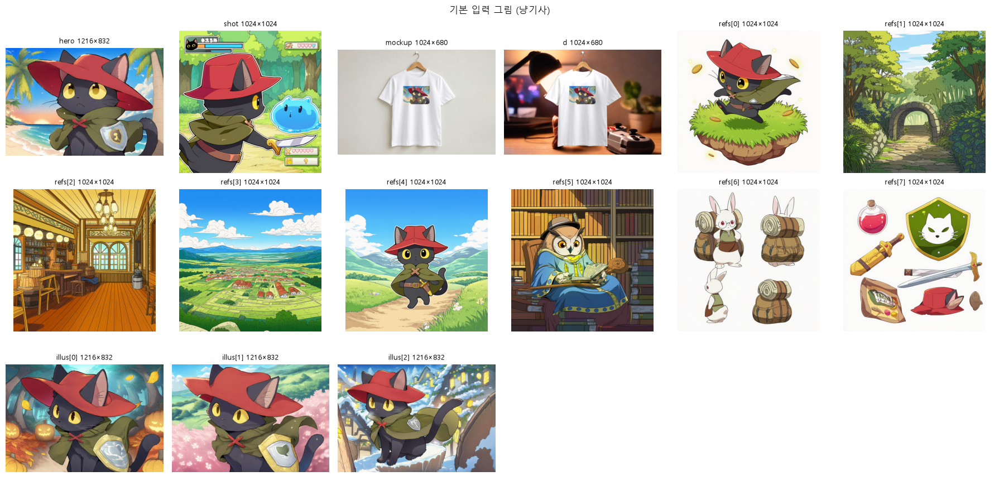

문구: {
 "eyebrow": "냥기사의 여행",
 "title": "빨간 모자 고양이 기사의 여정",
 "info": "냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임",
 "intro": "검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에서 여유롭게 서 있는, 동화책 같은 손그림 색감의 2D 어드벤처 게임입니다. / 11월 업데이트로 신규 동료가 추가되어 더 풍부한 모험을 경험할 수 있어요.",
 "sns": "빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 냥기사의 여행을 지금 만나보세요.",
 "mock_text": "빨간 모자를 쓴 고양이 기사가 돌담 위에 앉아 있는 모습이 귀엽고 따뜻해요. 옆에 누워 있는 토끼와 함께 푸른 풀밭과 돌담이 어우러진 동화 같은 세계를 걷고 있어요.",
 "d_text": "빨간 모자와 녹색 망토를 걸친 고양이 기사가, 풀섬의 햇살 아래 조용히 기다리고 있어. 옆에 앉은 토끼가 웃는 얼굴로, 이 작은 모험의 시작을 기대하고 있어.",
 "purchase": {
  "상품명": "냥기사의 여행 일러스트 티셔츠",
  "판매가": "29,000원",
  "옵션": "S / M / L / XL",
  "배송비": "3,000원",
  "출고": "주문 후 3일 이내"
 }
}


In [6]:
# 기본(냥기사) 입력 그림
names = ['hero', 'shot', 'mockup', 'd'] + [f'refs[{i}]' for i in range(len(A['refs']))] + [f'illus[{i}]' for i in range(len(A['illus']))]
paths = [A['hero'], A['shot'], A['mockup'], A['d']] + A['refs'] + A['illus']
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for ax in axes.flat:
    ax.axis('off')
for ax, n, p in zip(axes.flat, names, paths):
    im = Image.open(p)
    ax.imshow(im)
    ax.set_title(f'{n} {im.size[0]}×{im.size[1]}', fontsize=9)
fig.suptitle('기본 입력 그림 (냥기사)')
plt.tight_layout()
plt.show()
print('문구:', json.dumps({k: (v if k != 'intro' else ' / '.join(v)) for k, v in TEXTS.items()}, ensure_ascii=False, indent=1))

## 실행

In [7]:
cfg = dict(out_dir=str(OUT_DIR.resolve()), fonts=FONTS, assets=A, texts=TEXTS, run_html=HAS_PW)
(OUT_DIR / 'ds_config.json').write_text(json.dumps(cfg, ensure_ascii=False, indent=1), encoding='utf-8')
t_run = time.perf_counter()
# 진행 줄을 셀 출력에 바로 보여 주고 같은 내용을 ds_run.log에 남김
with open(OUT_DIR / 'ds_run.log', 'w', encoding='utf-8') as log_f:
    p = subprocess.Popen([sys.executable, str(CHILD_DIR / 'run26.py'), str(OUT_DIR / 'ds_config.json')], stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    for line in p.stdout:
        print(line, end='', flush=True)
        log_f.write(line)
        log_f.flush()
    p.wait()
print('종료 코드', p.returncode, '| 전체', round(time.perf_counter() - t_run, 1), '초')

[09:45:51 | 경과    0.8초] Chromium 시작 0.14초
[09:45:54 | 경과    3.7초]  1/30 01 기본(냥기사) | 1번 문제 0 (뺀 글자 0) 0.883초 | 2번 문제 0 1.604초
[09:45:56 | 경과    6.2초]  2/30 02 KayKit C 그림 | 1번 문제 0 (뺀 글자 0) 0.754초 | 2번 문제 0 1.476초
[09:45:59 | 경과    8.8초]  3/30 03 0x72 C 그림 | 1번 문제 0 (뺀 글자 0) 0.739초 | 2번 문제 0 1.514초
[09:46:02 | 경과   11.5초]  4/30 04 긴 제목(한글) | 1번 문제 0 (뺀 글자 0) 0.724초 | 2번 문제 0 1.564초
[09:46:04 | 경과   14.1초]  5/30 05 띄어쓰기 없는 제목 | 1번 문제 0 (뺀 글자 0) 0.746초 | 2번 문제 0 1.513초
[09:46:07 | 경과   16.7초]  6/30 06 긴 제목(영어) | 1번 문제 0 (뺀 글자 0) 0.791초 | 2번 문제 0 1.524초
[09:46:09 | 경과   19.2초]  7/30 07 긴 게임 이름(이름표) | 1번 문제 0 (뺀 글자 0) 0.702초 | 2번 문제 0 1.477초
[09:46:12 | 경과   21.8초]  8/30 08 긴 부제 | 1번 문제 0 (뺀 글자 0) 0.726초 | 2번 문제 0 1.501초
[09:46:15 | 경과   24.4초]  9/30 09 이모지 제목 | 1번 문제 0 (뺀 글자 3) 0.706초 | 2번 문제 0 1.504초
[09:46:17 | 경과   27.0초] 10/30 10 긴 본문·URL | 1번 문제 0 (뺀 글자 0) 0.776초 | 2번 문제 0 1.512초
[09:46:19 | 경과   29.3초] 11/30 11 일러스트 0장 | 1번 문제 0 (뺀 글자 0) 0.634초 | 2번 문제 0 1.36초
[09:46:22 | 경과   31.7초

## 결과 표

In [8]:
res = pd.read_csv(OUT_DIR / 'ds_results.csv', keep_default_na=False)
res['problems'] = pd.to_numeric(res.problems)
for c in ['dropped', 'sec', 'height']:
    res[c] = pd.to_numeric(res[c], errors='coerce')
ok = res[res.problems >= 0]
summary = ok.groupby('engine').agg(시험수=('case', 'size'), 문제있는_시험=('problems', lambda s: int((s > 0).sum())), 문제합=('problems', 'sum'),
                                   뺀글자합=('dropped', 'sum'), 평균초=('sec', 'mean'), 최대초=('sec', 'max'))
display(summary.round(3))
err = res[res.problems < 0]
if len(err):
    print('실행 못 한 시험:')
    display(err[['case', 'engine', 'error']])
table = res.pivot(index='case', columns='engine', values=['problems', 'dropped', 'sec', 'height', 'theme'])
display(table)
bad = ok[(ok.problems > 0) | (ok.dropped > 0)]
print('문제·뺀 글자가 있는 시험:', 0 if bad.empty else len(bad))
for _, r in bad.iterrows():
    print(f'- {r.case} [{r.engine}] 문제 {r.problems}, 뺀 글자 {r.dropped}: {r.detail[:300]}')

,시험수,문제있는_시험,문제합,뺀글자합,평균초,최대초
engine,,,,,,
1 Pillow,30,0,0,3,0.704,0.898
2 HTML,30,0,0,0,1.447,1.636


problems         dropped             sec          height  \
engine             1 Pillow 2 HTML 1 Pillow 2 HTML 1 Pillow 2 HTML 1 Pillow   
case                                                                          
01 기본(냥기사)                0      0        0      0    0.883  1.604     5843   
02 KayKit C 그림            0      0        0      0    0.754  1.476     5843   
03 0x72 C 그림              0      0        0      0    0.739  1.514     5843   
04 긴 제목(한글)               0      0        0      0    0.724  1.564     5843   
05 띄어쓰기 없는 제목             0      0        0      0    0.746  1.513     5843   
06 긴 제목(영어)               0      0        0      0    0.791  1.524     5843   
07 긴 게임 이름(이름표)           0      0        0      0    0.702  1.477     5843   
08 긴 부제                   0      0        0      0    0.726  1.501     5887   
09 이모지 제목                 0      0        3      0    0.706  1.504     5843   
10 긴 본문·URL               0      0        0      0    0.776  1.512     6653   
11 일러스트 0장                0      0        0      0    0.634   1.36     5153   
12 일러스트 1장                0      0        0      0     0.67  1.435     5843   
13 일러스트 2장                0      0        0      0    0.719  1.475     5843   
14 일러스트 4장                0      0        0      0    0.762  1.496     5879   
15 일러스트 5장                0      0        0      0    0.756  1.552     6117   
16 일러스트 9장                0      0        0      0    0.889  1.636     6593   
17 레퍼런스 0장·스샷 없음          0      0        0      0    0.443  1.212     4427   
18 레퍼런스 1장                0      0        0      0    0.559  1.382     5723   
19 레퍼런스 13장               0      0        0      0    0.898   1.56     6215   
20 스샷 없음(C 결과로 대신)        0      0        0      0    0.696  1.443     5618   
21 가로 3:1 그림 전부           0      0        0      0    0.505  1.044     4693   
22 세로 1:3 그림 전부           0      0        0      0    0.601  1.173     6856   
23 64px 작은 그림             0      0        0      0    0.465  1.317     5723   
24 무채색 대표 그림              0      0        0      0    0.726  1.449     5843   
25 검정 대표 그림               0      0        0      0     0.68  1.383     5843   
26 흰색 대표 그림               0      0        0      0    0.701  1.339     5843   
27 구매 정보 긴 값              0      0        0      0     0.71  1.519     5890   
28 구매 정보 빈 값              0      0        0      0      0.7  1.487     5649   
29 구매 정보 일부만              0      0        0      0    0.716  1.491     5746   
30 문구 빈 값                 0      0        0      0    0.734  1.469     4944   

                             theme           
engine             2 HTML 1 Pillow   2 HTML  
case                                         
01 기본(냥기사)           5818    image    image  
02 KayKit C 그림       5818    image    image  
03 0x72 C 그림         5818    image    image  
04 긴 제목(한글)          5818    image    image  
05 띄어쓰기 없는 제목        5830    image    image  
06 긴 제목(영어)          5818    image    image  
07 긴 게임 이름(이름표)      5818    image    image  
08 긴 부제              5876    image    image  
09 이모지 제목            5818    image    image  
10 긴 본문·URL          6663    image    image  
11 일러스트 0장           5128    image    image  
12 일러스트 1장           5818    image    image  
13 일러스트 2장           5818    image    image  
14 일러스트 4장           5834    image    image  
15 일러스트 5장           6072    image    image  
16 일러스트 9장           6548    image    image  
17 레퍼런스 0장·스샷 없음     4436    image    image  
18 레퍼런스 1장           5698    image    image  
19 레퍼런스 13장          6190    image    image  
20 스샷 없음(C 결과로 대신)   5594    image    image  
21 가로 3:1 그림 전부      4670    image    image  
22 세로 1:3 그림 전부      6815    image    image  
23 64px 작은 그림        5698    image    image  
24 무채색 대표 그림         5818  default  default  
25 검정 대표 그림          5818  default  default  
26 흰색 대표 그림          5818  default  default  
27 구매 정보 긴 값         5865    image    image  
28 구매 정보 빈 값         5606    im

문제·뺀 글자가 있는 시험: 1
- 09 이모지 제목 [1 Pillow] 문제 0, 뺀 글자 3: 


## 그래프

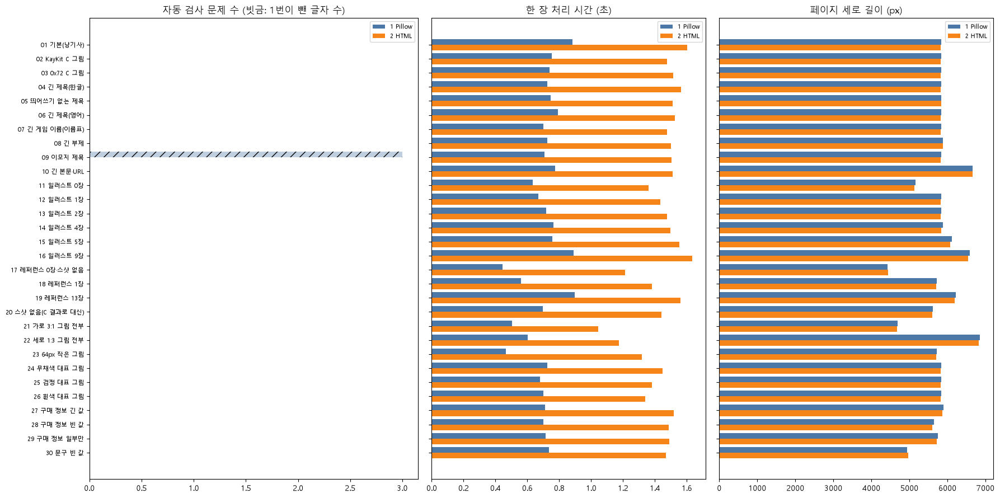

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 9), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
cases_ = list(dict.fromkeys(res.case))
y = np.arange(len(cases_))
for j, (eng, col) in enumerate([('1 Pillow', '#4c78a8'), ('2 HTML', '#f58518')]):
    d = res[res.engine == eng].set_index('case').reindex(cases_)
    ax[0].barh(y + (j - .5) * .4, d.problems.clip(lower=0), .4, color=col, label=eng)
    ax[0].barh(y + (j - .5) * .4, d.dropped.fillna(0), .4, left=d.problems.clip(lower=0), color=col, alpha=.35, hatch='//')
    ax[1].barh(y + (j - .5) * .4, d.sec, .4, color=col, label=eng)
    ax[2].barh(y + (j - .5) * .4, d.height, .4, color=col, label=eng)
ax[0].set_yticks(y, cases_, fontsize=8)
for a in ax[1:]:
    a.set_yticks(y, [''] * len(y))
for a in ax:
    a.invert_yaxis()
    a.legend(fontsize=8)
ax[0].set_title('자동 검사 문제 수 (빗금: 1번이 뺀 글자 수)')
ax[1].set_title('한 장 처리 시간 (초)')
ax[2].set_title('페이지 세로 길이 (px)')
plt.tight_layout()
fig.savefig(OUT_DIR / 'ds_summary.png', dpi=110)
plt.show()

## 눈 확인: 시험별 두 방식 (왼쪽 1번, 오른쪽 2번, 1/4 축소)

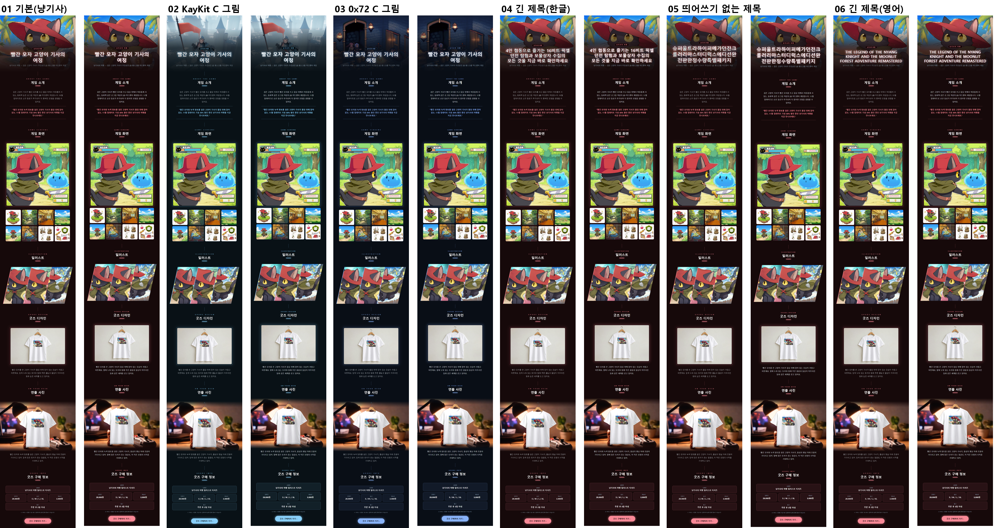

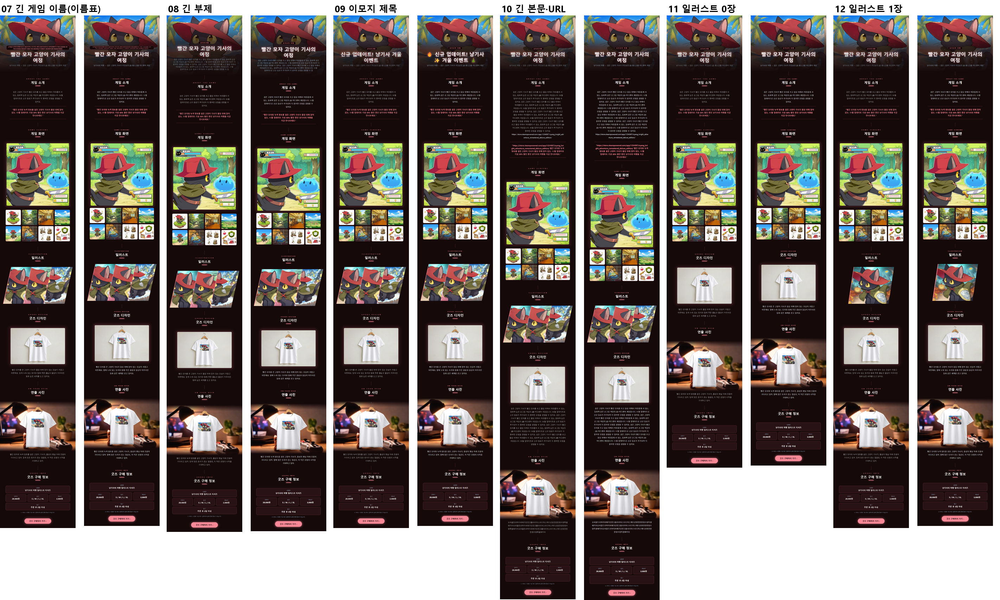

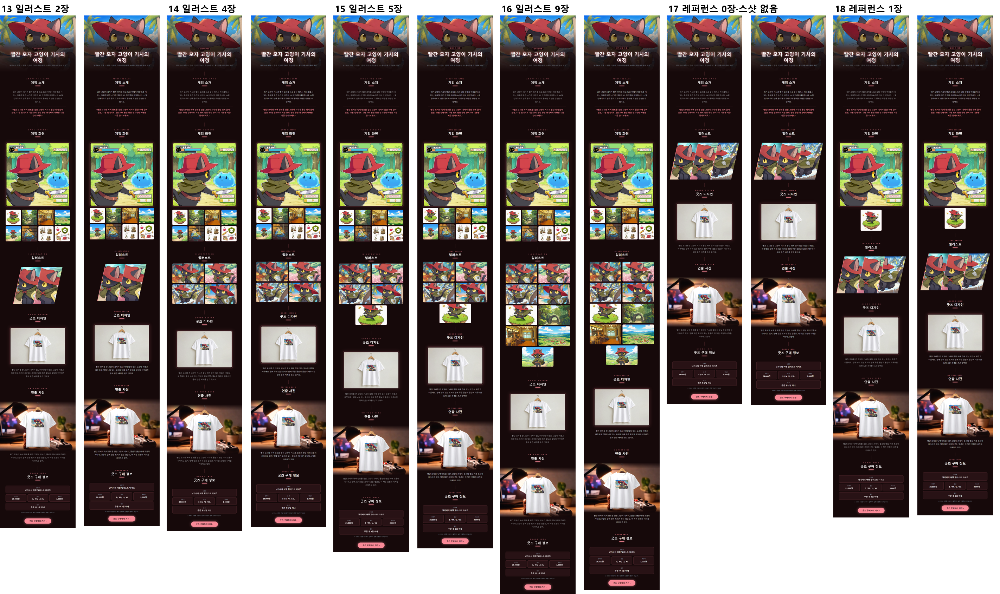

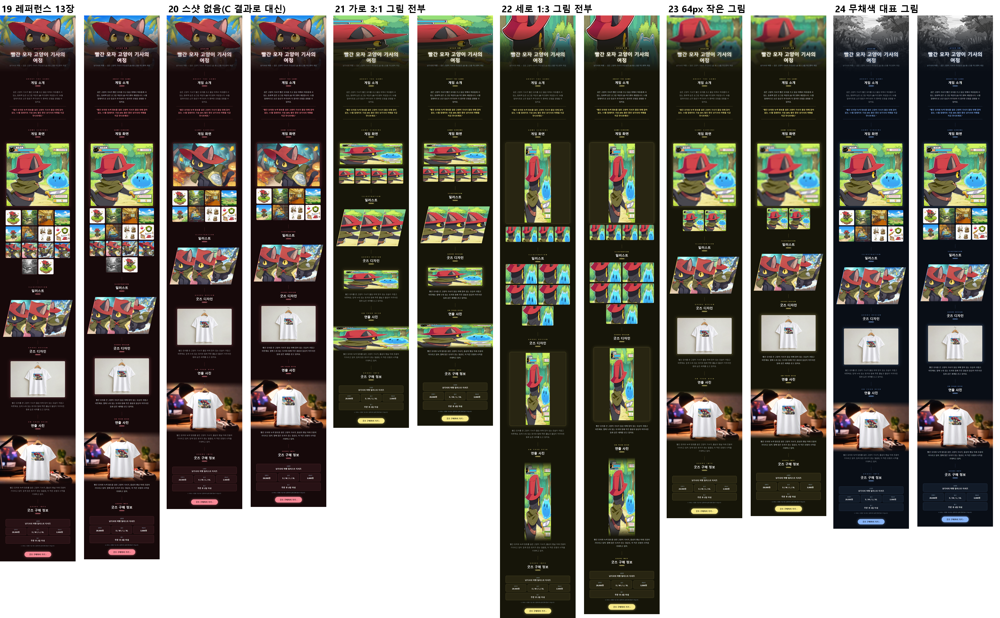

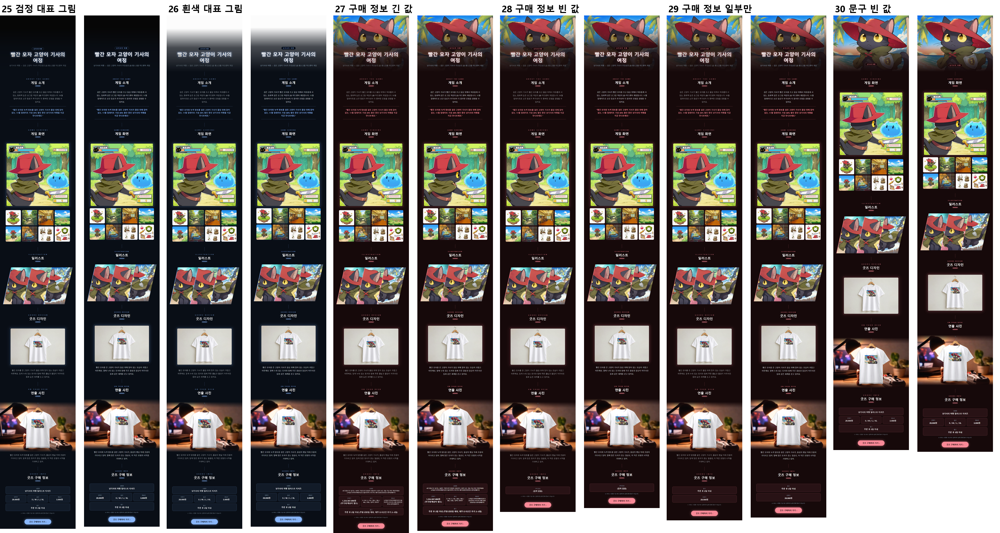

In [10]:
_f = ImageFont.truetype(FONTS['bold'][0], 26, index=FONTS['bold'][1])
for s0 in range(0, len(cases_), 6):
    tiles = []
    for name in cases_[s0:s0 + 6]:
        key = name.split()[0]
        ims = [Image.open(OUT_DIR / 'pages' / f'{e}_{key}.png') if (OUT_DIR / 'pages' / f'{e}_{key}.png').exists() else Image.new('RGB', (860, 400), 'gray')
               for e in ['pil', 'html']]
        ims = [im.resize((im.width // 4, im.height // 4)) for im in ims]
        t = Image.new('RGB', (ims[0].width + ims[1].width + 24, max(i.height for i in ims) + 44), 'white')
        ImageDraw.Draw(t).text((4, 6), name, font=_f, fill='black')
        t.paste(ims[0], (0, 44))
        t.paste(ims[1], (ims[0].width + 24, 44))
        tiles.append(t)
    sheet = Image.new('RGB', (sum(t.width for t in tiles) + 20 * len(tiles), max(t.height for t in tiles)), 'white')
    x = 0
    for t in tiles:
        sheet.paste(t, (x, 0))
        x += t.width + 20
    sheet.save(OUT_DIR / f'ds_sheet_{s0 // 6 + 1}.png')
    display(sheet)

## 눈 확인: 구역 확대 (왼쪽 1번, 오른쪽 2번)

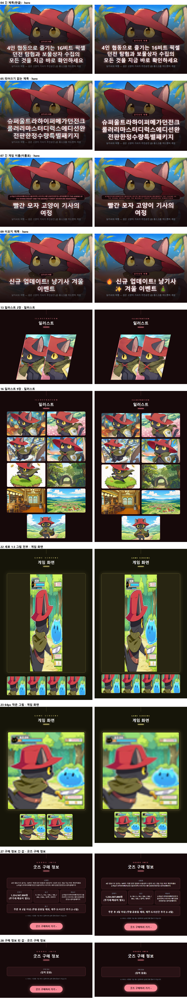

In [11]:
# 깨지기 쉬운 시험의 해당 구역만 잘라 비교
ZOOM = [('04 긴 제목(한글)', 'hero'), ('05 띄어쓰기 없는 제목', 'hero'), ('07 긴 게임 이름(이름표)', 'hero'), ('09 이모지 제목', 'hero'),
        ('13 일러스트 2장', '일러스트'), ('16 일러스트 9장', '일러스트'), ('22 세로 1:3 그림 전부', '게임 화면'), ('23 64px 작은 그림', '게임 화면'),
        ('27 구매 정보 긴 값', '굿즈 구매 정보'), ('28 구매 정보 빈 값', '굿즈 구매 정보')]


def crop(case, eng, sec):
    r = res[(res.case == case) & (res.engine == eng)]
    if r.empty or r.problems.iloc[0] < 0:
        return Image.new('RGB', (860, 200), 'gray')
    secs = {s[0]: s for s in json.loads(r.sections.iloc[0])}
    im = Image.open(OUT_DIR / 'pages' / f"{'pil' if eng.startswith('1') else 'html'}_{case.split()[0]}.png")
    _, y0, y1 = secs[sec]
    return im.crop((0, int(y0), 860, int(min(y1, y0 + 1400))))


rows = []
for case, sec in ZOOM:
    a, b = crop(case, '1 Pillow', sec), crop(case, '2 HTML', sec)
    t = Image.new('RGB', (860 * 2 + 20, max(a.height, b.height) + 44), 'white')
    ImageDraw.Draw(t).text((4, 6), f'{case} · {sec}', font=_f, fill='black')
    t.paste(a, (0, 44))
    t.paste(b, (880, 44))
    rows.append(t.resize((t.width // 2, t.height // 2)))
zoom = Image.new('RGB', (rows[0].width, sum(r.height for r in rows) + 10 * len(rows)), 'white')
y = 0
for r in rows:
    zoom.paste(r, (0, y))
    y += r.height + 10
zoom.save(OUT_DIR / 'ds_zoom.png')
display(zoom)